In [36]:
import warnings
warnings.filterwarnings("ignore")

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [38]:
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

In [39]:
df = pd.read_csv("data/customer_master.csv")

In [40]:
df.head()

,customer_id,customer_name,customer_age,gender,customer_segment,customer_city,customer_state,customer_country,region,customer_postal_code,customer_acquisition_cost
0,CUST-000001,Donna Miller,54,Female,Consumer,Laurenland,Dubai,UAE,South,11253,13.58
1,CUST-000002,Joseph James,61,Male,Consumer,Lake Peter,Lower Saxony,Germany,North,47778,27.45
2,CUST-000003,Daniel Smith,47,Male,Consumer,Seanview,North Rhine,Germany,West,13900,31.53
3,CUST-000004,David Lopez,30,Male,VIP,Hawkinshaven,Pennsylvania,USA,East,53984,16.02
4,CUST-000005,Dakota Davis,55,Female,Consumer,New Carlymouth,Florida,USA,South,50994,41.34


In [41]:
df.shape

(25000, 11)

In [42]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                25000 non-null  str    
 1   customer_name              25000 non-null  str    
 2   customer_age               25000 non-null  int64  
 3   gender                     25000 non-null  str    
 4   customer_segment           25000 non-null  str    
 5   customer_city              25000 non-null  str    
 6   customer_state             25000 non-null  str    
 7   customer_country           25000 non-null  str    
 8   region                     25000 non-null  str    
 9   customer_postal_code       25000 non-null  int64  
 10  customer_acquisition_cost  25000 non-null  float64
dtypes: float64(1), int64(2), str(8)
memory usage: 2.1 MB


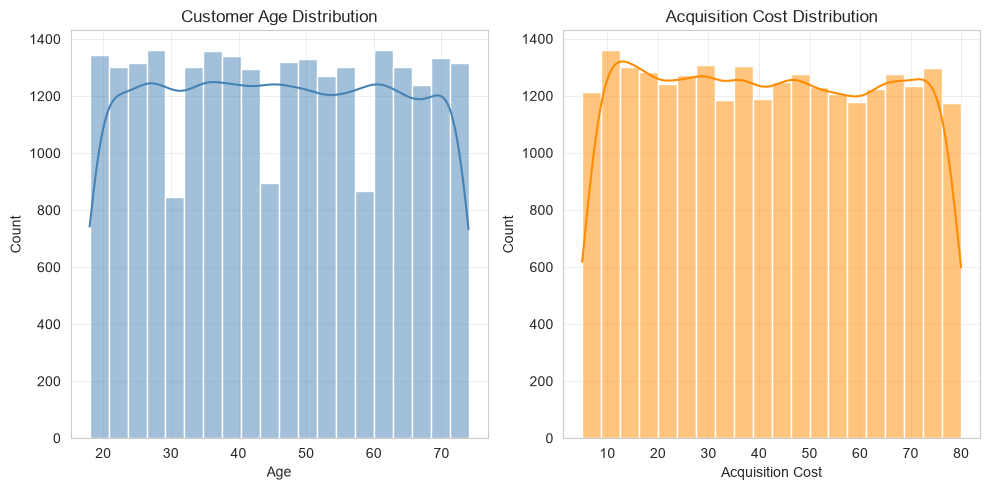

In [43]:
fig, axes = plt.subplots(1,2)
sns.histplot(df["customer_age"], bins=20, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Customer Age Distribution")
axes[0].set_xlabel("Age")

sns.histplot(df["customer_acquisition_cost"], bins=20, kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("Acquisition Cost Distribution")
axes[1].set_xlabel("Acquisition Cost")

plt.tight_layout()


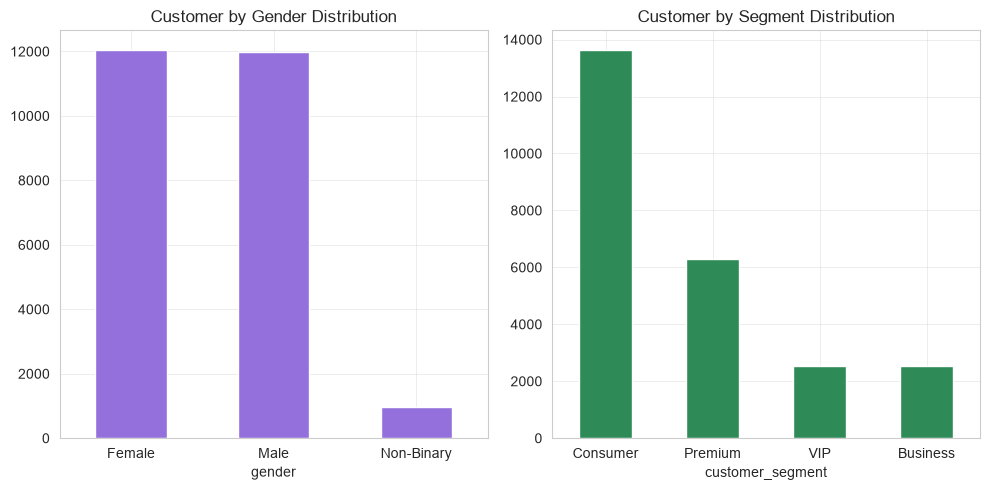

In [44]:
fig, axes = plt.subplots(1,2)

df['gender'].value_counts().plot(kind='bar', ax = axes[0], color='mediumpurple')
axes[0].set_title("Customer by Gender Distribution")
axes[0].tick_params(axis='x', rotation=0)

df["customer_segment"].value_counts().plot(kind='bar', ax=axes[1], color='seagreen')
axes[1].set_title("Customer by Segment Distribution")
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()

In [45]:
unique_ids = df["customer_id"].is_unique
duplicate_rows = df.duplicated().sum()
duplicate_names = df["customer_name"].duplicated().sum()

In [46]:
pd.Series({
    "customer id is unique": unique_ids,
    "duplicate rows": duplicate_rows,
    "duplicate names": duplicate_names
})

customer id is unique    True
duplicate rows              0
duplicate names          3369
dtype: object

In [47]:
country_summary = df.groupby("customer_country").agg(
    customer_count = ("customer_id", "count"),
    avg_age = ("customer_age", "mean"),
    avg_acquisition_cost = ("customer_acquisition_cost", "mean")
).sort_values("customer_count", ascending=False)

In [48]:
country_summary

,customer_count,avg_age,avg_acquisition_cost
customer_country,,,
USA,14925,45.928777,42.085881
UK,3701,45.883545,42.274712
Germany,2046,45.640762,42.217571
Canada,1279,46.275215,42.612651
Australia,1233,45.689376,42.972758
India,1041,46.024976,41.831585
UAE,775,45.909677,41.280594


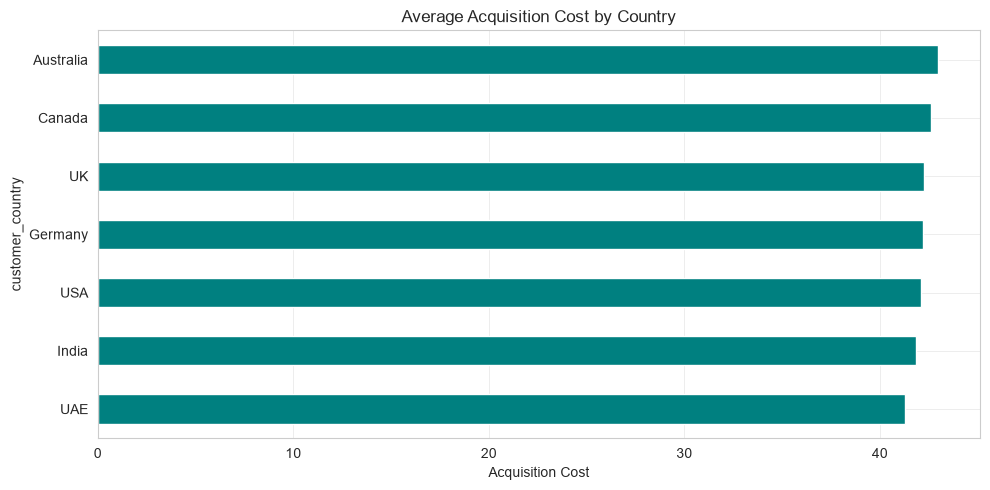

In [49]:
country_summary["avg_acquisition_cost"].sort_values().plot(kind="barh", color="teal")
plt.title("Average Acquisition Cost by Country")
plt.xlabel("Acquisition Cost")
plt.tight_layout()

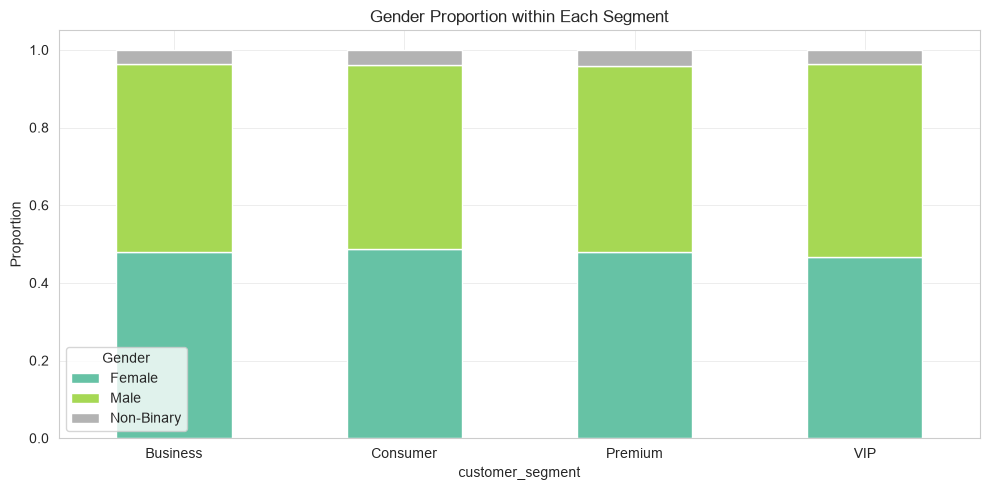

In [50]:
segment_gender = pd.crosstab(df["customer_segment"], df["gender"], normalize="index")
segment_gender.plot(kind = "bar", stacked=True, colormap="Set2")
plt.title("Gender Proportion within Each Segment")
plt.ylabel("Proportion")
plt.xticks(rotation=0)
plt.legend(title="Gender")
plt.tight_layout()

In [51]:
pivot = df.pivot_table(
    values="customer_acquisition_cost",
    index="region",
    columns="customer_segment",
    aggfunc="mean"
)

pivot

customer_segment,Business,Consumer,Premium,VIP
region,,,,
Central,42.665208,42.381241,42.033338,40.903996
East,41.582421,41.498164,42.068956,43.113654
North,43.024669,42.521355,42.938065,39.870359
South,42.419132,42.260161,41.927955,42.680490
West,42.257776,42.587711,41.129324,42.167195


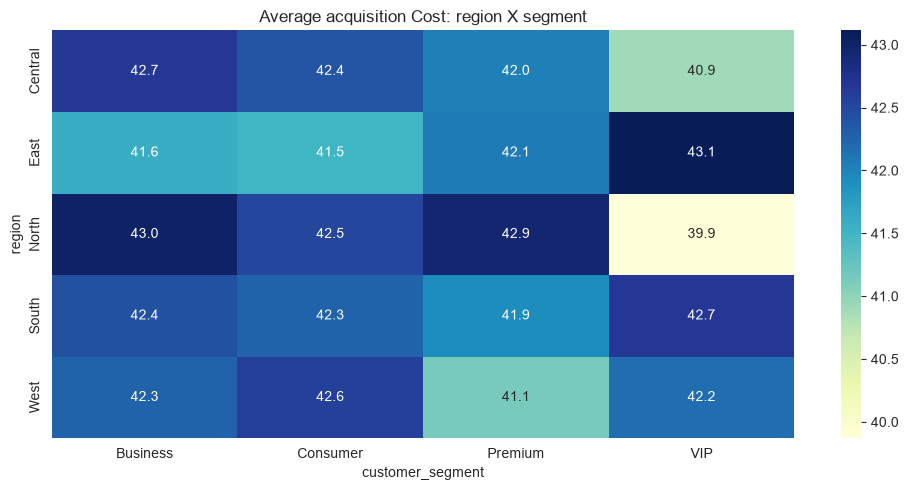

In [52]:
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Average acquisition Cost: region X segment")
plt.tight_layout()

In [53]:
df["postal_len"] = df["customer_postal_code"].astype(str).str.len()
postal_by_country = pd.crosstab(df["customer_country"], df["postal_len"])
postal_by_country

postal_len,3,4,5
customer_country,,,
Australia,6,106,1121
Canada,7,124,1148
Germany,7,183,1856
India,2,91,948
UAE,3,56,716
UK,19,324,3358
USA,80,1368,13477


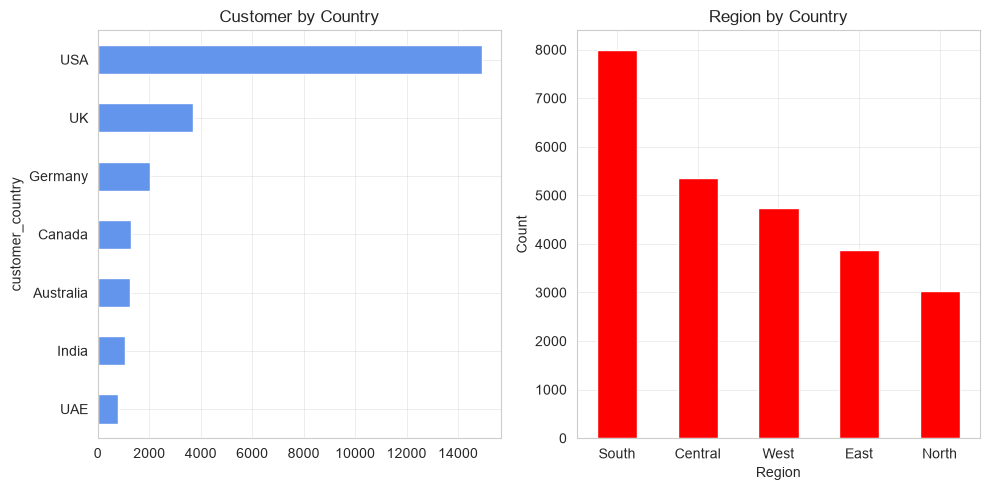

In [54]:
fig, axes = plt.subplots(1, 2)

df["customer_country"].value_counts().plot(kind='barh', ax=axes[0], color="cornflowerblue")
axes[0].set_title("Customer by Country")
axes[0].invert_yaxis()

df["region"].value_counts().plot(kind='bar', ax=axes[1], color="red")
axes[1].set_title("Region by Country")
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Count")
axes[1].tick_params(axis="x", rotation = 0)
plt.tight_layout()

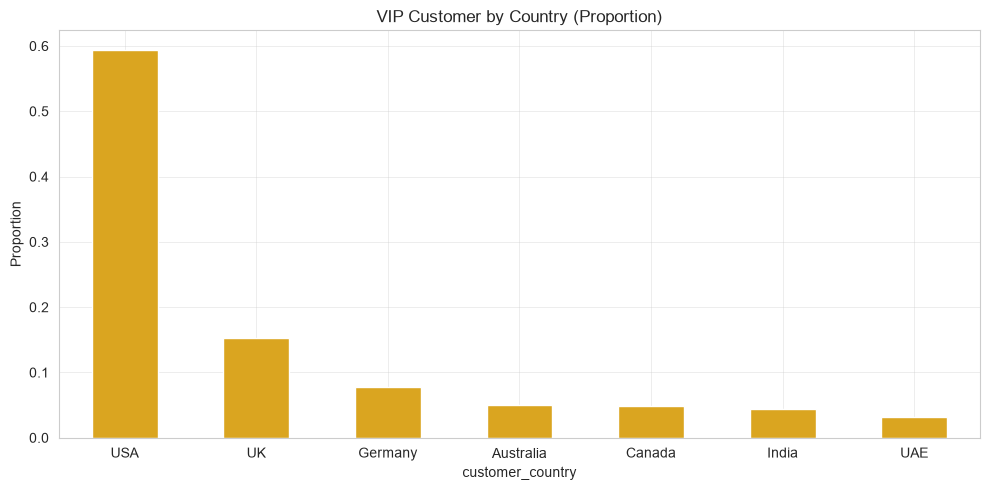

In [55]:
vip_by_country = df[df['customer_segment'] == 'VIP']['customer_country'].value_counts(normalize=True)

vip_by_country.plot(kind="bar", color="goldenrod")
plt.title("VIP Customer by Country (Proportion)")
plt.ylabel("Proportion")
plt.xticks(rotation=0)
plt.tight_layout()